# Jetsound: Sound detection with Jetson Nano

## Data collection and feature extraction

In [78]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
import librosa

#DATADIR = "FinalAssignment/dataset/"
DATADIR = "Haakons_testfolder/instrument_set/"
print(DATADIR)
CATEGORIES = ['Acoustic_guitar', 'Drum_set', 'vibraphone']

Haakons_testfolder/instrument_set/


Function to make spectrograms.

In [79]:
def convert_to_spectrogram(audio_signal, sample_rate, n_mels, fmax=8000):
    # audio_signal
    # sample_rate
    # n_mels : mels bins (Y-resolution of spectrogram)
    # fmax : maximum frequency in spectrogram

    # Returns a 4D tensorflow tensor (1, n_mels, time_steps, 1)
        
    # Create mel spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y = audio_signal,
        sr = sample_rate,
        n_mels = n_mels,
        fmax = fmax
    )
    
    # Convert to decibels
    mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

    # Normalize
    mel_spec = (mel_spec - mel_spec.min()) / (mel_spec.max() - mel_spec.min())

    # Add channel dimension
    return mel_spec[..., np.newaxis]  # shape: (n_mels, time_steps, 1)

    # Add batch dimension
    #return mel_spec[np.newaxis, ...]

In [ ]:
# # without test set
# dataset = []
# test_dataset = []
# N_MELS = 128 # Y resolution of the spectrograms (basically image height)
# T_SAMP = 300 # X resolution of the spectrograms (basically image width)
# LOSO_ID = 5  # Which recording to leave out

# def create_dataset(limit):
#     for category in CATEGORIES:
#         path = os.path.join(DATADIR, category)
#         class_num = CATEGORIES.index(category) #Assigns category 0 to Claps, 1 to Keyboard and 2 to Keys
#         for audio_sample in os.listdir(path):
            
#             # Check that audio file is wav
#             if not audio_sample.lower().endswith(".wav"):
#                 continue

#             name = os.path.splitext(audio_sample)[0]
#             #print(name)

#             try:
#                 prefix = name.split("_")[0]      # Claps5
#                 recording_id = int(prefix.replace(category, ""))
#             except ValueError:
#                 print(f"Skipping (bad name): {audio_sample}")
#                 continue

#             # ---- LOSO: skip 5th recording ----
#             if recording_id == LOSO_ID:
#                 try:
#                     audio, sr = librosa.load(os.path.join(path, audio_sample))
#                     spectro = convert_to_spectrogram(audio, sr, N_MELS, fmax=8000)
#                     test_dataset.append([spectro, class_num, sr]) # Appends the category to the array
#                     #print("Appended:")
#                     #print(audio_sample)
#                 except Exception as e:
#                     pass
#                 continue

#             if len(dataset)>limit:
#                 print("MAX LIMIT EXCEEDED")
#                 return
#             try:
#                 audio, sr = librosa.load(os.path.join(path, audio_sample))
#                 spectro = convert_to_spectrogram(audio, sr, N_MELS, fmax=8000)
#                 dataset.append([spectro, class_num, sr]) # Appends the category to the array
#                 print("Appended:")
#                 print(audio_sample)
#             except Exception as e:
#                 pass



# create_dataset(5000)

# print("Length of dataset: " +  str(len(dataset)))

KeyboardInterrupt: 

In [92]:
# Rewritten By geppetto:

dataset = []
test_dataset = []

N_MELS = 128
T_SAMP = 150
LOSO_ID = 3  # Which recording to leave out

def create_dataset(limit):
    global dataset, test_dataset
    dataset = []
    test_dataset = []

    for category in CATEGORIES:
        path = os.path.join(DATADIR, category)
        class_num = CATEGORIES.index(category)

        print(f"\nProcessing category: {category}")

        for audio_sample in sorted(os.listdir(path)):

            if not audio_sample.lower().endswith(".wav"):
                continue

            name = os.path.splitext(audio_sample)[0]

            try:
                prefix = name.split("_")[0]  # e.g. Claps5
                recording_id = int(prefix.replace(category, ""))
            except ValueError:
                print(f"Skipping (bad name): {audio_sample}")
                continue

            try:
                audio, sr = librosa.load(os.path.join(path, audio_sample), sr=None)
                spectro = convert_to_spectrogram(audio, sr, N_MELS, fmax=8000)
                #if recording_id == LOSO_ID:
                print(len(audio_sample))
                if len(audio_sample) < 7: # Debug for instrument audio
                    test_dataset.append([spectro, class_num, sr])
                    print(audio_sample)
                else:
                    if len(dataset) >= limit:
                        print("MAX LIMIT EXCEEDED")
                        return
                    dataset.append([spectro, class_num, sr])

            except Exception as e:
                print(f"Failed to load {audio_sample}: {e}")

create_dataset(5000)

print("Train size:", len(dataset))
print("Test size:", len(test_dataset))



Processing category: Acoustic_guitar
5
1.wav
6
10.wav
7
7
7
7
7
7
7
7
7
7
6
11.wav
7
7
7
7
7
7
7
7
7
7
6
12.wav
7
7
7
7
7
7
7
7
7
7
6
13.wav
7
7
7
7
7
7
7
7
7
7
6
14.wav
7
7
7
7
7
7
7
7
7
7
6
15.wav
7
7
7
7
7
7
7
7
7
7
6
16.wav
7
7
7
7
7
7
7
7
7
7
6
17.wav
7
7
7
7
7
7
7
7
7
7
6
18.wav
7
7
7
7
7
7
7
7
7
7
6
19.wav
7
7
7
7
7
7
7
7
7
7
5
2.wav
6
20.wav
7
7
7
7
7
7
7
7
7
7
6
21.wav
7
7
7
7
7
7
7
7
7
7
6
22.wav
7
7
7
7
7
7
7
7
7
7
6
23.wav
7
7
7
7
7
7
7
7
7
7
6
24.wav
7
7
7
7
7
7
7
7
7
7
6
25.wav
7
7
7
7
7
7
7
7
7
7
6
26.wav
7
7
7
7
7
7
7
7
7
7
6
27.wav
7
7
7
7
7
7
7
7
7
7
6
28.wav
7
7
7
7
7
7
7
7
7
7
6
29.wav
7
7
7
7
7
7
7
7
7
7
5
3.wav
6
30.wav
7
7
7
7
7
7
7
7
7
7
6
31.wav
7
7
7
7
7
7
7
7
7
7
6
32.wav
7
7
7
7
7
7
7
7
7
7
6
33.wav
7
7
7
7
7
7
7
7
7
7
6
34.wav
7
7
7
7
7
7
7
7
7
7
6
35.wav
7
7
7
7
7
7
7
7
7
7
6
36.wav
7
7
7
7
7
7
7
7
7
7
6
37.wav
7
7
7
7
7
7
7
7
7
7
6
38.wav
7
7
7
7
7
7
7
7
7
7
6
39.wav
7
7
7
7
7
7
7
7
7
7
5
4.wav
6
40.wav
7
7
7
7
7
7
7
7
7
7
6
41.wav
7
7
7
7
7
7
7
7
7
7
6


In [93]:
# AI sanity check
from collections import Counter

print("\nTRAIN label distribution:")
print(Counter([d[1] for d in dataset]))

print("\nTEST label distribution:")
print(Counter([d[1] for d in test_dataset]))



TRAIN label distribution:
Counter({1: 500, 0: 433, 2: 410})

TEST label distribution:
Counter({0: 99, 1: 99, 2: 96})


Show example from new dataset


Number of mel bins (n_mels): 128
Number of samples (time-steps) in one entry: 130
Category: Acoustic_guitar


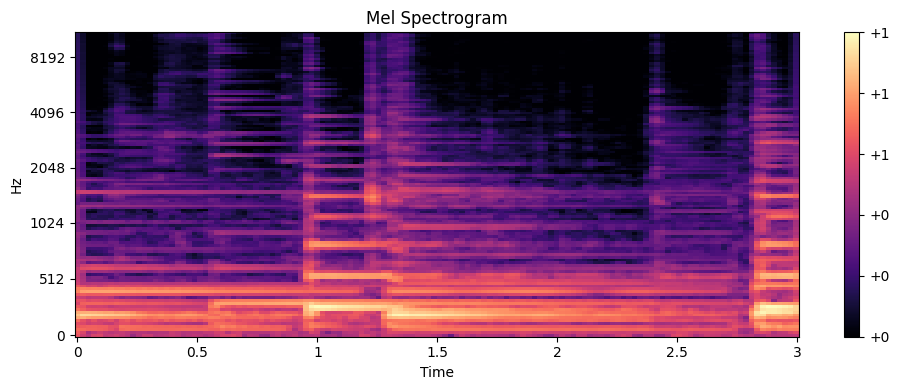

In [94]:
CHOSEN_EXAMPLE = 100

spec_tensor = dataset[CHOSEN_EXAMPLE][0]  # shape: ( n_mels, time_steps, 1)
n_mels, time_steps, channels = spec_tensor.shape
print("Number of mel bins (n_mels):", n_mels)
print("Number of samples (time-steps) in one entry:", time_steps)
print("Category: " + CATEGORIES[dataset[CHOSEN_EXAMPLE][1]])

# Remove batch and channel dimensions
spec = dataset[CHOSEN_EXAMPLE][0]
spec = spec[:, :, 0]

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    spec,
    x_axis="time",
    y_axis="mel",
    sr=dataset[CHOSEN_EXAMPLE][2]
)
plt.colorbar(format="%+2.0f")
plt.title("Mel Spectrogram")
plt.tight_layout()
plt.show()

Shuffle the dataset and make sure by looking at the labels.

In [95]:
import random

random.shuffle(dataset)

# choose an arbitrary size and truncate
MAX_SAMPLES = 9000
dataset = dataset[:MAX_SAMPLES]
print(f"Shuffled and truncated dataset to {len(dataset)} samples.")

for sample in dataset[:10]:
    print(sample[1])

Shuffled and truncated dataset to 1343 samples.
1
1
1
1
0
0
0
2
2
0


Create your train and test split.

In [96]:
x_train, y_train = [],[]
x_test, y_test = [],[]

# Train set
for spectrogram, label, samplerate in dataset:
    x_train.append(spectrogram)  #Place all images in x
    y_train.append(label)     #Place all labels in y

# LOSO test set
for spectrogram, label, sr in test_dataset:
    x_test.append(spectrogram)
    y_test.append(label)

x_train = np.array(x_train)
y_train = np.array(y_train)
x_test  = np.array(x_test)
y_test  = np.array(y_test)

print("x_train shape:", x_train.shape)
print("x_test shape :", x_test.shape)
print("Train labels:", Counter(y_train))
print("Test labels :", Counter(y_test))


x_train shape: (1343, 128, 130, 1)
x_test shape : (294, 128, 130, 1)
Train labels: Counter({np.int64(1): 500, np.int64(0): 433, np.int64(2): 410})
Test labels : Counter({np.int64(0): 99, np.int64(1): 99, np.int64(2): 96})


## Network architecture

## Model training

In [98]:
# Model definition (simplified & regularized)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

input_shape = x_train.shape[1:]  # (n_mels, time_steps, 1)

model = Sequential([
    # Conv Block 1
    Conv2D(16, (7,3), activation='relu', padding='same', kernel_regularizer=l2(1e-4), input_shape=input_shape),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 2
    Conv2D(32, (3,3), activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.3),
    
    # Conv Block 3
    Conv2D(64, (3,3), activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    GlobalAveragePooling2D(),  # reduces parameters and prevents overfitting
    
    # Dense + Output
    Dense(32, activation='relu', kernel_regularizer=l2(1e-4)),
    BatchNormalization(),
    Dropout(0.4),
    
    Dense(len(CATEGORIES), activation='softmax')
])

# Use a smaller learning rate to stabilise training
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_25 (Conv2D)              │ (None, 128, 130, 16)   │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 128, 130, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 64, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 64, 65, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 64, 65, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 64, 65, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,243 (102.51 KB)

 Trainable params: 25,955 (101.39 KB)

 Non-trainable params: 288 (1.12 KB)

Epoch 1/10


42/42 - 7s - 162ms/step - accuracy: 0.6307 - loss: 0.8509 - val_accuracy: 0.3367 - val_loss: 1.1300 - learning_rate: 1.0000e-05
Epoch 2/10
42/42 - 7s - 158ms/step - accuracy: 0.7312 - loss: 0.6937 - val_accuracy: 0.3367 - val_loss: 1.1319 - learning_rate: 1.0000e-05
Epoch 3/10


42/42 - 7s - 166ms/step - accuracy: 0.7803 - loss: 0.6490 - val_accuracy: 0.4184 - val_loss: 1.1213 - learning_rate: 1.0000e-05
Epoch 4/10


42/42 - 7s - 163ms/step - accuracy: 0.8213 - loss: 0.5120 - val_accuracy: 0.3469 - val_loss: 1.0989 - learning_rate: 1.0000e-05
Epoch 5/10


42/42 - 6s - 149ms/step - accuracy: 0.8667 - loss: 0.4556 - val_accuracy: 0.3469 - val_loss: 1.0608 - learning_rate: 1.0000e-05
Epoch 6/10


42/42 - 6s - 150ms/step - accuracy: 0.8697 - loss: 0.4199 - val_accuracy: 0.3503 - val_loss: 0.9898 - learning_rate: 1.0000e-05
Epoch 7/10


42/42 - 6s - 149ms/step - accuracy: 0.8757 - loss: 0.4142 - val_accuracy: 0.3878 - val_loss: 0.8991 - learning_rate: 1.0000e-05
Epoch 8/10


42/42 - 6s - 148ms/step - accuracy: 0.8727 - loss: 0.4115 - val_accuracy: 0.4864 - val_loss: 0.7914 - learning_rate: 1.0000e-05
Epoch 9/10


42/42 - 6s - 150ms/step - accuracy: 0.8757 - loss: 0.3947 - val_accuracy: 0.5680 - val_loss: 0.6853 - learning_rate: 1.0000e-05
Epoch 10/10


42/42 - 6s - 151ms/step - accuracy: 0.8898 - loss: 0.3535 - val_accuracy: 0.6531 - val_loss: 0.5380 - learning_rate: 1.0000e-05
10/10 - 0s - 25ms/step - accuracy: 0.6531 - loss: 0.5380
Test loss: 0.5380, Test accuracy: 0.6531


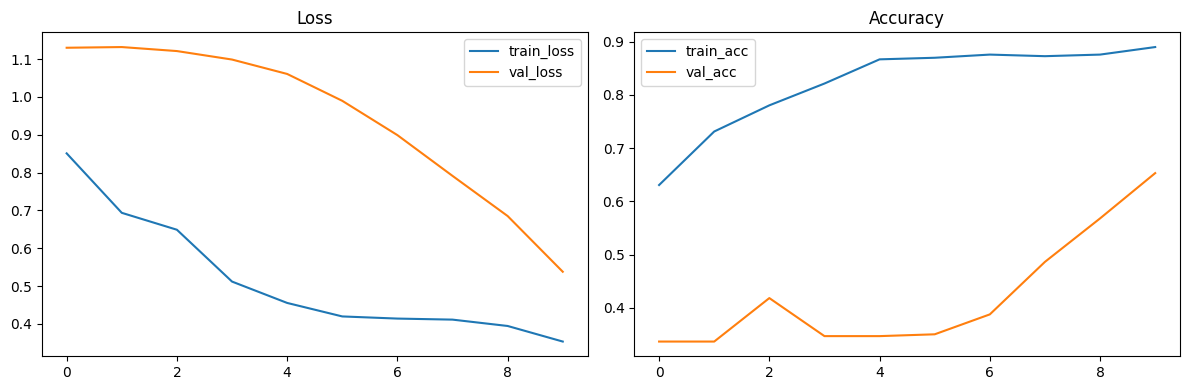

In [100]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# Training config
EPOCHS = 10
checkpoint_cb = ModelCheckpoint('best_model.h5', save_best_only=True, monitor='val_loss', mode='min')
earlystop_cb = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
reduce_lr_cb = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    #batch_size=batch,
    validation_data=(x_test, y_test),
    callbacks=[checkpoint_cb, earlystop_cb, reduce_lr_cb],
    verbose=2
)

# Evaluate and save final model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")
#model.save("final_model.h5")

# Plot training history
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend(); plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.legend(); plt.title('Accuracy')

plt.tight_layout()
plt.show()

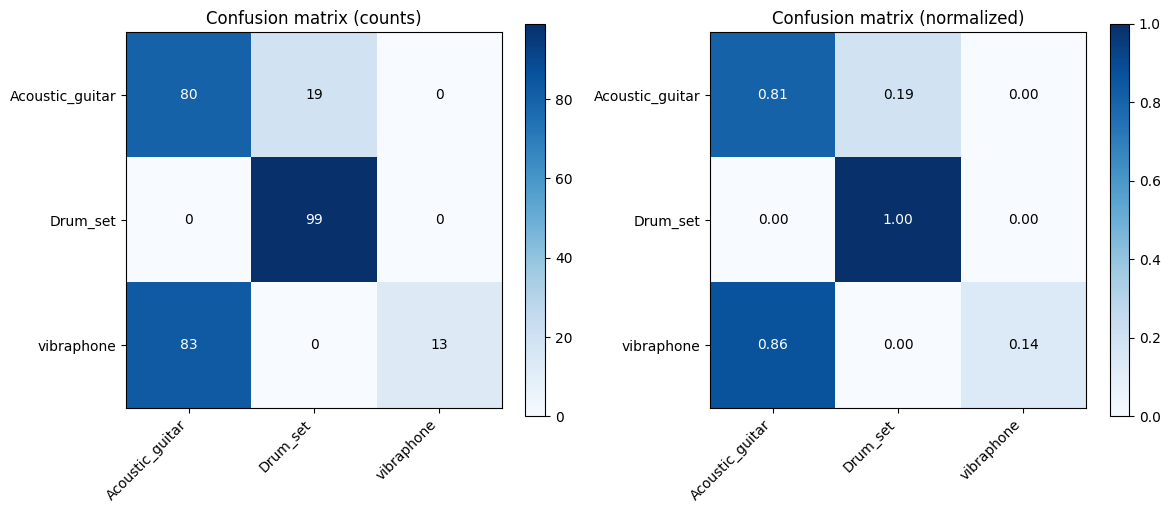

Classification report:
Using in-memory model instance


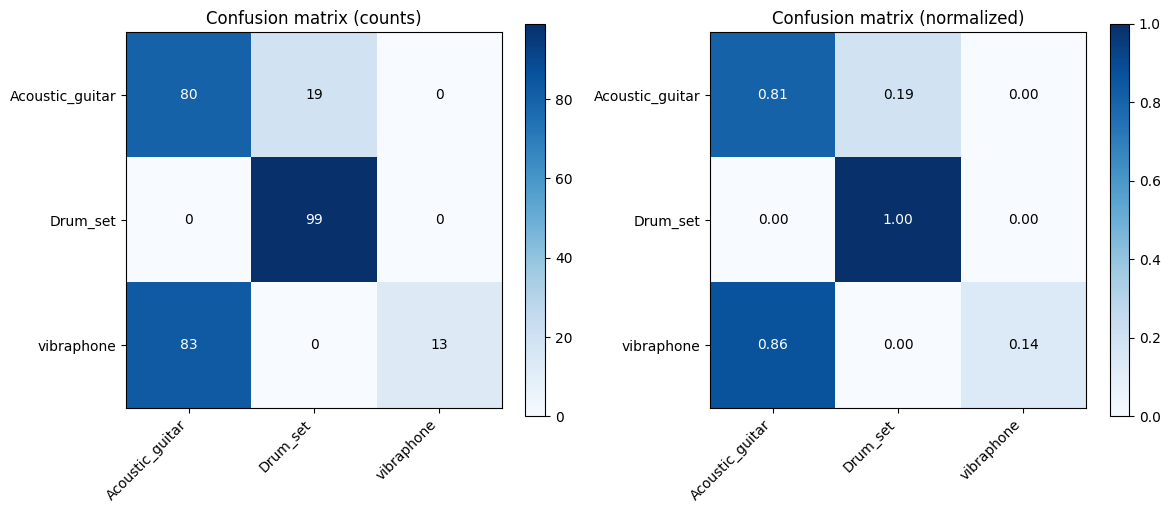

Classification report:
                 precision    recall  f1-score   support

Acoustic_guitar       0.49      0.81      0.61        99
       Drum_set       0.84      1.00      0.91        99
     vibraphone       1.00      0.14      0.24        96

       accuracy                           0.65       294
      macro avg       0.78      0.65      0.59       294
   weighted avg       0.77      0.65      0.59       294



In [101]:
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import load_model
import os
import numpy as np

# Confusion matrix and classification report for the trained model

import matplotlib.pyplot as plt

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
import matplotlib.pyplot as plt

# Use in-memory model instance
if 'model' not in globals():
    raise RuntimeError("No model instance found in memory. Train or load a model before running this cell.")
else:
    print("Using in-memory model instance")

# Predict labels for the test set
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compute confusion matrix (counts) and normalized version
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-12)  # avoid div by zero

# Plot both count and normalized confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Counts
im0 = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title("Confusion matrix (counts)")
plt.colorbar(im0, ax=axes[0])
ticks = np.arange(len(CATEGORIES))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[0].set_yticklabels(CATEGORIES)
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, f"{cm[i, j]:d}",
                     ha='center', va='center',
                     color='white' if cm[i, j] > thresh else 'black')

# Normalized
im1 = axes[1].imshow(cm_norm, interpolation='nearest', cmap=plt.cm.Blues, vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized)")
plt.colorbar(im1, ax=axes[1])
axes[1].set_xticks(ticks); axes[1].set_yticks(ticks)
axes[1].set_xticklabels(CATEGORIES, rotation=45, ha='right')
axes[1].set_yticklabels(CATEGORIES)
for i in range(cm_norm.shape[0]):
    for j in range(cm_norm.shape[1]):
        axes[1].text(j, i, f"{cm_norm[i, j]:.2f}",
                     ha='center', va='center',
                     color='white' if cm_norm[i, j] > 0.5 else 'black')

plt.tight_layout()
plt.show()

# Print classification report
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=CATEGORIES))

Categories: ['Claps', 'Keyboard', 'Keys']
Total samples in dataset: 612
Label counts (all): Counter({1: 204, 0: 204, 2: 204})
Label counts (train): Counter({np.int64(1): 204, np.int64(0): 204, np.int64(2): 204})
Label counts (test): Counter({np.int64(0): 51, np.int64(1): 51, np.int64(2): 51})
Predicted class distribution on test set: Counter({np.int64(0): 153})
Mean predicted probability per class: [0.4105812  0.26860154 0.32081717]
First 10 test sample predictions (true, pred, probs):
0 0 0 ['0.408', '0.270', '0.322']
1 0 0 ['0.411', '0.269', '0.320']
2 0 0 ['0.410', '0.269', '0.321']
3 0 0 ['0.409', '0.269', '0.322']
4 0 0 ['0.411', '0.269', '0.320']
5 0 0 ['0.410', '0.269', '0.321']
6 0 0 ['0.409', '0.269', '0.321']
7 0 0 ['0.413', '0.268', '0.320']
8 0 0 ['0.410', '0.269', '0.321']
9 0 0 ['0.412', '0.268', '0.320']
Last train acc: 0.46078431606292725 val_acc: 0.3333333432674408


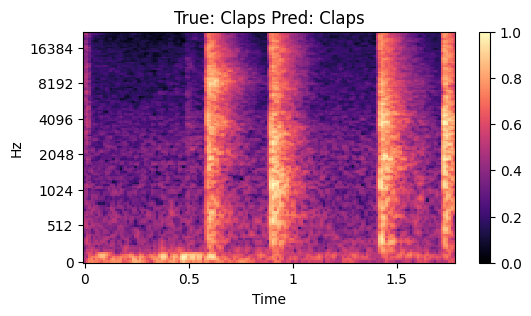

In [70]:
# Diagnostic checks for class balance and predictions
from collections import Counter
import numpy as np

print("Categories:", CATEGORIES)

# Dataset label counts
try:
    print("Total samples in dataset:", len(dataset))
    print("Label counts (all):", Counter([label for _, label, _ in dataset]))
except Exception as e:
    print("Could not compute dataset counts:", e)

# Train/test label counts
try:
    print("Label counts (train):", Counter(y_train))
    print("Label counts (test):", Counter(y_test))
except Exception as e:
    print("Could not compute train/test counts:", e)

# Prediction distribution and probabilities
try:
    y_prob = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    print("Predicted class distribution on test set:", Counter(y_pred))
    print("Mean predicted probability per class:", np.mean(y_prob, axis=0))
    print("First 10 test sample predictions (true, pred, probs):")
    for i in range(min(10, len(y_prob))):
        print(i, y_test[i], y_pred[i], [f"{p:.3f}" for p in y_prob[i]])
except Exception as e:
    print("Prediction step failed:", e)

# Training history quick look
try:
    if 'history' in globals():
        print("Last train acc:", history.history.get('accuracy')[-1], "val_acc:", history.history.get('val_accuracy')[-1])
except Exception as e:
    print("Could not read training history:", e)

# Show one example spectrogram with prediction
try:
    sample_idx = 0
    spec = np.squeeze(x_test[sample_idx])
    import matplotlib.pyplot as plt
    plt.figure(figsize=(6,3))
    librosa.display.specshow(spec, x_axis='time', y_axis='mel', sr=dataset[sample_idx][2] if len(dataset)>sample_idx else None)
    plt.title(f"True: {CATEGORIES[y_test[sample_idx]]} Pred: {CATEGORIES[y_pred[sample_idx]]}")
    plt.colorbar()
    plt.show()
except Exception as e:
    print("Plotting failed:", e)

In [11]:
# Corrected diagnostics (avoid relying on model.input)
from collections import Counter
import numpy as np

eps = 1e-12
# Predictions
y_prob_train = model.predict(x_train, verbose=0)
y_pred_train = np.argmax(y_prob_train, axis=1)

y_prob_test = model.predict(x_test, verbose=0)
y_pred_test = np.argmax(y_prob_test, axis=1)

print("Train predicted distribution:", Counter(y_pred_train))
print("Test predicted distribution:", Counter(y_pred_test))
print("Mean train probs:", np.mean(y_prob_train, axis=0))
print("Mean test probs:", np.mean(y_prob_test, axis=0))

# Approximate logits via log-softmax (monotonic transform)
logits_train_approx = np.log(np.clip(y_prob_train, eps, 1.0))
logits_test_approx = np.log(np.clip(y_prob_test, eps, 1.0))
print("Mean approx logits (train):", np.mean(logits_train_approx, axis=0))
print("Mean approx logits (test):", np.mean(logits_test_approx, axis=0))

# Per-sample statistics to detect normalization issues
train_std_mean = np.mean([s.std() for s in x_train])
test_std_mean = np.mean([s.std() for s in x_test])
print("Mean per-sample std: train", train_std_mean, "test", test_std_mean)
const_train = sum(1 for s in x_train if np.isclose(s.std(), 0.0))
const_test = sum(1 for s in x_test if np.isclose(s.std(), 0.0))
print("Constant samples train/test:", const_train, const_test)

# Try to locate original dataset indices for the first few test samples (small dataset so brute-force is OK)
def find_original_index(sample):
    for idx, (spec, label, sr) in enumerate(dataset):
        if np.allclose(spec, sample):
            return idx
    return None

for i in range(min(5, len(x_test))):
    orig = find_original_index(x_test[i])
    print(f"test idx {i}, orig idx: {orig}, true {y_test[i]} ({CATEGORIES[y_test[i]]}), pred {y_pred_test[i]} ({CATEGORIES[y_pred_test[i]]})")

# Quick note based on earlier bias print:
print('\nConclusion hint:')
print(' - Final-layer biases were small (near zero).')
print(' - The collapse to class 0 is unlikely caused by a large bias; more likely: overfitting or training dynamics (e.g., skewed minibatches, aggressive LR, insufficient regularization).')
print(' - Next: try re-running with class-balanced batches, lower LR, or more regularization; or evaluate the saved checkpoint `best_model.h5` to compare.')

Train predicted distribution: Counter({np.int64(0): 347, np.int64(2): 4})
Test predicted distribution: Counter({np.int64(0): 39})
Mean train probs: [0.34622788 0.31791538 0.33585683]
Mean test probs: [0.3466149  0.31789404 0.33549112]
Mean approx logits (train): [-1.0606815 -1.1459748 -1.0910866]
Mean approx logits (test): [-1.0595618 -1.1460415 -1.0921715]
Mean per-sample std: train 0.17310569 test 0.16711944
Constant samples train/test: 0 0
test idx 0, orig idx: 9, true 1 (Keyboard), pred 0 (Claps)
test idx 1, orig idx: 42, true 1 (Keyboard), pred 0 (Claps)
test idx 2, orig idx: 33, true 2 (Keys), pred 0 (Claps)
test idx 3, orig idx: 311, true 0 (Claps), pred 0 (Claps)
test idx 4, orig idx: 272, true 0 (Claps), pred 0 (Claps)

Conclusion hint:
 - Final-layer biases were small (near zero).
 - The collapse to class 0 is unlikely caused by a large bias; more likely: overfitting or training dynamics (e.g., skewed minibatches, aggressive LR, insufficient regularization).
 - Next: try re-r

In [45]:
print("Test label counts:", Counter(y_test))

Test label counts: Counter({np.int64(0): 26, np.int64(1): 26, np.int64(2): 26})


## Validation

You need the library "pyaudio" to test this feature.

    pip install pyaudio
    
    conda install conda-forge::pyaudio

In [ ]:
import pyaudio
import wave

# Configuration parameters
FORMAT = pyaudio.paInt16  # 16-bit resolution
CHANNELS = 1              # Mono recording
RATE = 44100              # Sample rate (44.1kHz is standard)
CHUNK = 1024              # Buffer size
RECORD_SECONDS = 5        # Duration of recording
OUTPUT_FILENAME = "test_recording.wav"

audio = pyaudio.PyAudio()

# Start Recording
stream = audio.open(format=FORMAT, channels=CHANNELS,
                    rate=RATE, input=True,
                    frames_per_buffer=CHUNK)

print("Recording...")

frames = []

for i in range(0, int(RATE / CHUNK * RECORD_SECONDS)):
    data = stream.read(CHUNK)
    frames.append(data)

print("Finished recording.")

# Stop and close the stream
stream.stop_stream()
stream.close()
audio.terminate()

# Save the recorded data as a WAV file 
# (THIS NEEDS TO BE CHANGED SO IT IS STORED IN MEMORY TO BE USED IN REAL TIME)
with wave.open(OUTPUT_FILENAME, 'wb') as wf:
    wf.setnchannels(CHANNELS)
    wf.setsampwidth(audio.get_sample_size(FORMAT))
    wf.setframerate(RATE)
    wf.writeframes(b''.join(frames))

print(f"File saved as {OUTPUT_FILENAME}")

ModuleNotFoundError: No module named 'pyaudio'

# Inputs and Outputs

This is an LED test code

In [ ]:
# This is a test code for the LED

import Jetson.GPIO as GPIO
import time

LED_PIN = 18  # GPIO pin number where the LED is connected

GPIO.setmode(GPIO.BCM)
GPIO.setup(LED_PIN, GPIO.OUT)

try:
    print("LED ON")
    GPIO.output(LED_PIN, GPIO.HIGH)  # Turn LED on
    time.sleep(2)                     # Keep it on for 2 seconds
    print("LED OFF")
    GPIO.output(LED_PIN, GPIO.LOW)   # Turn LED off
finally:

    GPIO.cleanup()  # Clean up GPIO settings
